# Probability bounds and admissible radii (Figures 4 and 5)

Lower bounds on the probability that the absolute error stays within a
tolerance $\varepsilon$, jointly over the field and two independent Gaussian
inputs, and the largest radii at which each bound reaches a target confidence.

Output: `figs/probability_bounds_combined.{pdf,png}`,
`figs/radius_dimension.{pdf,png}` and the plotted values in
`figs/probability_bounds_data.csv` and `figs/radius_dimension_data.csv`.

In [1]:
import csv

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

from bigf import bounds, inputs, profiles
from bigf.paths import FIG_DIR, relative
from bigf.plotting import BLUE, GRAY, ORANGE, SERIF_STYLE, save_figure

ELL = 1.0
EPSILON = 0.1
INPUT_COVERAGE = 0.99
JOINT_CONFIDENCE = 0.95
FIELD_CONFIDENCE = inputs.field_confidence(JOINT_CONFIDENCE, INPUT_COVERAGE)

PROFILES = [
    profiles.get_profile(name, ELL)
    for name in ("squared_exponential", "rational_quadratic", "matern_7_2", "matern_9_2")
]

FIG4_DIMENSIONS = (2, 16, 64)
NORMALIZED_RADII = np.geomspace(0.035, 0.35, 1201)

DIMENSION_TICKS = (2, 4, 8, 16, 32, 64, 128, 256)
FIG5_DIMENSIONS = np.arange(DIMENSION_TICKS[0], DIMENSION_TICKS[-1] + 1)

print(f"Figure 4: {NORMALIZED_RADII.size} radii, D = {FIG4_DIMENSIONS}")
print(f"Figure 5: D = {FIG5_DIMENSIONS[0]} to {FIG5_DIMENSIONS[-1]}")
print(f"Required field confidence for Figure 5: {FIELD_CONFIDENCE:.6f}")
for profile in PROFILES:
    print(f"{profile.name:<22} gamma3 = {profile.gamma3:.6f}")

Figure 4: 1201 radii, D = (2, 16, 64)
Figure 5: D = 2 to 256
Required field confidence for Figure 5: 0.959596
squared_exponential    gamma3 = 1.000000
rational_quadratic     gamma3 = 6.000000
matern_7_2             gamma3 = 8.333333
matern_9_2             gamma3 = 3.266667


## Figure 4: joint probability bounds

In [2]:
FIG4_RADII = ELL * NORMALIZED_RADII
FIG4_BOUNDS = {
    (dimension, profile.name): inputs.joint_probability_bounds(
        profile, FIG4_RADII, dimension, EPSILON, INPUT_COVERAGE
    )
    for dimension in FIG4_DIMENSIONS
    for profile in PROFILES
}

print(f"Figure 4 data ready: {len(FIG4_BOUNDS)} panels, "
      f"{FIG4_RADII.size} radii per panel.")

Figure 4 data ready: 12 panels, 1201 radii per panel.


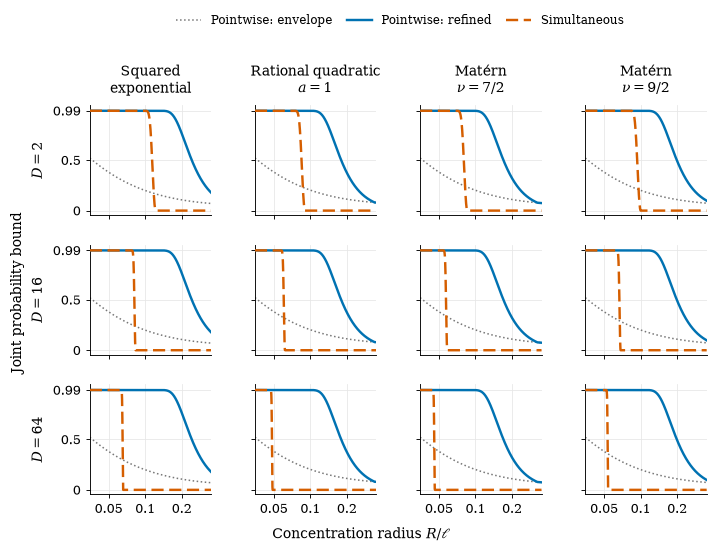

Saved: figs/probability_bounds_combined.pdf
Saved: figs/probability_bounds_combined.png
Saved: figs/probability_bounds_data.csv


In [3]:
FIG4_TITLES = {
    "squared_exponential": "Squared\nexponential",
    "rational_quadratic": "Rational quadratic\n" + r"$a=1$",
    "matern_7_2": "Matérn\n" + r"$\nu=7/2$",
    "matern_9_2": "Matérn\n" + r"$\nu=9/2$",
}

figure4_csv = FIG_DIR / "probability_bounds_data.csv"
figure4_rows = []

with plt.rc_context({**SERIF_STYLE, "legend.fontsize": 8.6}):
    fig4, axes = plt.subplots(
        len(FIG4_DIMENSIONS), len(PROFILES), figsize=(7.05, 5.60),
        sharex=True, sharey=True, squeeze=False
    )
    fig4.subplots_adjust(
        left=0.115, right=0.99, bottom=0.12, top=0.815,
        hspace=0.27, wspace=0.36
    )

    for row, dimension in enumerate(FIG4_DIMENSIONS):
        q_d = inputs.chi2_quantile(dimension, INPUT_COVERAGE)
        variances = inputs.input_variance(FIG4_RADII, dimension, INPUT_COVERAGE)

        for col, profile in enumerate(PROFILES):
            ax = axes[row, col]
            original, refined, simultaneous = FIG4_BOUNDS[dimension, profile.name]

            ax.plot(NORMALIZED_RADII, original, color=GRAY,
                    lw=1.1, ls=":", zorder=2)
            ax.plot(NORMALIZED_RADII, refined, color=BLUE, lw=1.75, zorder=3)
            ax.plot(NORMALIZED_RADII, simultaneous, color=ORANGE,
                    lw=1.75, ls=(0, (5, 2.3)), zorder=4)

            ax.set_xscale("log")
            ax.set_xlim(NORMALIZED_RADII[0], NORMALIZED_RADII[-1])
            ax.set_ylim(-0.045, 1.045)
            ax.set_yticks([0, 0.5, INPUT_COVERAGE],
                          labels=["0", "0.5", f"{INPUT_COVERAGE:g}"])
            ax.xaxis.set_major_locator(FixedLocator([0.05, 0.1, 0.2]))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
            ax.xaxis.set_minor_locator(NullLocator())
            ax.tick_params(axis="both", length=3, width=0.65)
            ax.grid(True, color="#E6E6E6", linewidth=0.55)

            if row == 0:
                ax.set_title(FIG4_TITLES[profile.name], pad=9)
            if col == 0:
                ax.set_ylabel(rf"$D={dimension}$", labelpad=5)

            figure4_rows.extend(
                (profile.family, profile.shape, dimension, EPSILON, ELL,
                 INPUT_COVERAGE, q_d, r, r / ELL, variance,
                 p_original, p_refined, p_sim)
                for r, variance, p_original, p_refined, p_sim in zip(
                    FIG4_RADII, variances, original, refined, simultaneous
                )
            )

    handles = [
        Line2D([], [], color=GRAY, lw=1.1, ls=":", label="Pointwise: envelope"),
        Line2D([], [], color=BLUE, lw=1.75, label="Pointwise: refined"),
        Line2D([], [], color=ORANGE, lw=1.75, ls=(0, (5, 2.3)),
               label="Simultaneous"),
    ]
    fig4.legend(handles=handles, loc="upper center",
                bbox_to_anchor=(0.555, 0.997), ncol=3, frameon=False,
                handlelength=2.1, columnspacing=1.2)
    fig4.text(0.012, 0.48, "Joint probability bound",
              rotation=90, va="center", ha="center", fontsize=10)
    fig4.supxlabel(r"Concentration radius $R/\ell$", y=0.035, fontsize=10)

    figure4_pdf, figure4_png = save_figure(
        fig4, "probability_bounds_combined", dpi=220,
        bbox_inches="tight", pad_inches=0.045,
    )
    plt.show()
    plt.close(fig4)

with figure4_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow((
        "family", "shape", "D", "epsilon", "ell", "input_pair_coverage", "q_D",
        "R", "R_over_ell", "input_coordinate_variance", "joint_pointwise_envelope",
        "joint_pointwise_refined", "joint_simultaneous",
    ))
    writer.writerows(figure4_rows)

for path in (figure4_pdf, figure4_png, figure4_csv):
    print(f"Saved: {relative(path)}")

## Figure 5: admissible radii

In [4]:
FIG5_RADII = {
    profile.name: bounds.admissible_radii(
        profile, FIG5_DIMENSIONS, EPSILON, FIELD_CONFIDENCE
    )
    for profile in PROFILES
}

print(f"Figure 5 data ready: {len(FIG5_RADII)} profiles, "
      f"{FIG5_DIMENSIONS.size} dimensions.")

Figure 5 data ready: 4 profiles, 255 dimensions.


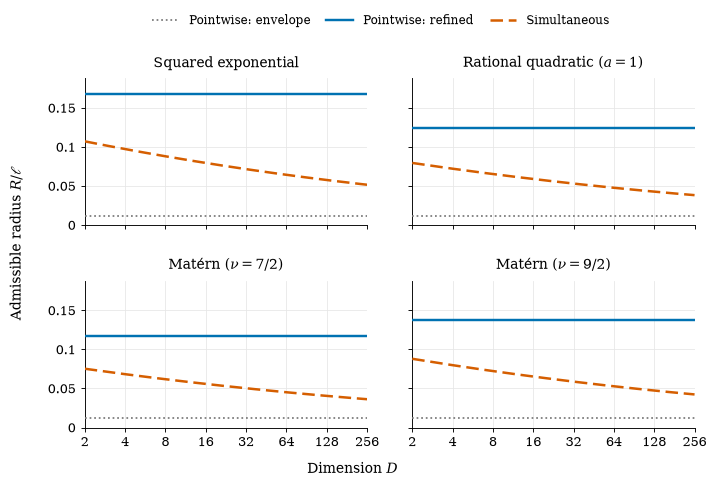

Saved: figs/radius_dimension.pdf
Saved: figs/radius_dimension.png
Saved: figs/radius_dimension_data.csv


In [5]:
figure5_csv = FIG_DIR / "radius_dimension_data.csv"
figure5_rows = []

with plt.rc_context({**SERIF_STYLE, "legend.fontsize": 8.8}):
    fig5, axes = plt.subplots(
        2, 2, figsize=(7.05, 4.85), sharex=True, sharey=True
    )
    fig5.subplots_adjust(
        left=0.12, right=0.985, bottom=0.12, top=0.84,
        hspace=0.38, wspace=0.16
    )

    for ax, profile in zip(axes.flat, PROFILES):
        envelope, refined, simultaneous = FIG5_RADII[profile.name]

        ax.axhline(envelope / ELL, color=GRAY, lw=1.25, ls=":", zorder=3)
        ax.axhline(refined / ELL, color=BLUE, lw=1.75, zorder=3)
        ax.plot(FIG5_DIMENSIONS, simultaneous / ELL, color=ORANGE,
                lw=1.8, ls=(0, (5, 2.3)), zorder=4)

        ax.set_xscale("log", base=2)
        ax.set_xlim(DIMENSION_TICKS[0], DIMENSION_TICKS[-1])
        ax.xaxis.set_major_locator(FixedLocator(DIMENSION_TICKS))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_title(profile.label, pad=8)
        ax.tick_params(axis="both", length=3, width=0.65)
        ax.grid(True, color="#E6E6E6", linewidth=0.55)

        for d in DIMENSION_TICKS:
            index = np.searchsorted(FIG5_DIMENSIONS, d)
            q_d = inputs.chi2_quantile(d, INPUT_COVERAGE)
            r_sim = simultaneous[index]
            figure5_rows.append((
                profile.name, d, EPSILON, JOINT_CONFIDENCE, INPUT_COVERAGE,
                FIELD_CONFIDENCE, q_d, ELL, envelope, refined, r_sim,
                envelope / ELL, refined / ELL, r_sim / ELL,
                envelope**2 / q_d, refined**2 / q_d, r_sim**2 / q_d,
            ))

    largest_radius = max(radii[1] / ELL for radii in FIG5_RADII.values())
    axes[0, 0].set_ylim(0.0, 1.12 * largest_radius)
    axes[0, 0].yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:g}"))

    handles = [
        Line2D([], [], color=GRAY, lw=1.25, ls=":", label="Pointwise: envelope"),
        Line2D([], [], color=BLUE, lw=1.75, label="Pointwise: refined"),
        Line2D([], [], color=ORANGE, lw=1.8, ls=(0, (5, 2.3)),
               label="Simultaneous"),
    ]
    fig5.legend(handles=handles, loc="upper center",
                bbox_to_anchor=(0.54, 0.995), ncol=3, frameon=False,
                handlelength=2.2, columnspacing=1.3)
    fig5.supylabel(r"Admissible radius $R/\ell$", x=0.014, fontsize=10)
    fig5.supxlabel(r"Dimension $D$", y=0.018, fontsize=10)

    figure5_pdf, figure5_png = save_figure(
        fig5, "radius_dimension", dpi=220,
        bbox_inches="tight", pad_inches=0.045,
    )
    plt.show()
    plt.close(fig5)

with figure5_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow((
        "kernel", "D", "epsilon", "joint_confidence", "input_pair_coverage",
        "field_confidence", "q_D", "ell", "R_envelope", "R_refined",
        "R_simultaneous", "R_envelope_over_ell", "R_refined_over_ell",
        "R_simultaneous_over_ell", "lambda_envelope", "lambda_refined",
        "lambda_simultaneous",
    ))
    writer.writerows(figure5_rows)

for path in (figure5_pdf, figure5_png, figure5_csv):
    print(f"Saved: {relative(path)}")